# 06 — Analyse RRF et combinaison pondérée

Fusion BM25 + Dense via Reciprocal Rank Fusion (RRF) standard et pondéré, sur MS MARCO dev.

## 1. Setup, chargement des runs et des qrels

In [1]:
import json
import sys
import warnings
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# Palette de couleurs
COLORS = ['#e30513', '#ffc103', '#0099ff', '#515151', '#f7a941', '#51a27e', '#702e78', '#7b003d']

# Répertoire de sortie
OUTPUT_DIR = Path('../results/analysis/06_rrf_weighted')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Style matplotlib
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('seaborn-whitegrid')

print('Setup terminé.')

Setup terminé.


In [2]:
def load_run(path):
    """Charge un fichier run.json. Format : {qid: [[pid, score], ...]}."""
    p = Path(path)
    if not p.exists():
        print(f'[AVERTISSEMENT] Run introuvable : {p}')
        return {}
    with open(p) as f:
        return json.load(f)


# Chargement des runs BM25 et dense
bm25_run = load_run('../results/baselines/bm25_msmarco_dev/run.json')
dense_run = load_run('../results/dense/evaluation/dense_bge_base_ft_subset10_msmarco_dev/run.json')

print(f'BM25 : {len(bm25_run)} requêtes')
print(f'Dense : {len(dense_run)} requêtes')

BM25 : 6980 requêtes
Dense : 6980 requêtes


In [3]:
# Chargement des qrels via dataset_factory
qrels = {}
try:
    sys.path.insert(0, '..')
    from src.data.dataset_factory import get_dataset
    dataset = get_dataset('msmarco', data_dir='../data/')
    qrels = dataset.load_qrels('dev')
    print(f'Qrels chargés : {len(qrels)} requêtes')
except Exception as e:
    print(f'[AVERTISSEMENT] Impossible de charger les qrels via dataset_factory : {e}')
    print('Certaines métriques ne pourront pas être calculées.')

Qrels chargés : 6980 requêtes


## 2. Implémentation de la fusion RRF

In [4]:
def rrf_fusion(results_a, results_b, k=60):
    """
    Reciprocal Rank Fusion standard.
    results_a, results_b : dict {qid: [[pid, score], ...]}
    k : constante de lissage RRF
    Retourne : dict {qid: [[pid, rrf_score], ...]} trié par score décroissant
    """
    # Union des requêtes communes aux deux runs
    all_qids = set(results_a.keys()) & set(results_b.keys())
    fused = {}
    for qid in all_qids:
        scores = defaultdict(float)
        # Contribution du run A
        for rank, (pid, _) in enumerate(results_a[qid], start=1):
            scores[pid] += 1.0 / (k + rank)
        # Contribution du run B
        for rank, (pid, _) in enumerate(results_b[qid], start=1):
            scores[pid] += 1.0 / (k + rank)
        # Tri décroissant
        fused[qid] = sorted(scores.items(), key=lambda x: -x[1])
    return fused


def weighted_rrf(results_a, results_b, w1=1.0, w2=1.0, k=60):
    """
    RRF pondéré : score = w1/(k+rank_a) + w2/(k+rank_b).
    w1, w2 : poids respectifs des runs A et B
    """
    all_qids = set(results_a.keys()) & set(results_b.keys())
    fused = {}
    for qid in all_qids:
        scores = defaultdict(float)
        for rank, (pid, _) in enumerate(results_a[qid], start=1):
            scores[pid] += w1 / (k + rank)
        for rank, (pid, _) in enumerate(results_b[qid], start=1):
            scores[pid] += w2 / (k + rank)
        fused[qid] = sorted(scores.items(), key=lambda x: -x[1])
    return fused


def compute_mrr_at_10(run, qrels):
    """
    Calcule le MRR@10 à partir d'un run fusionné et des qrels.
    run : dict {qid: [(pid, score), ...]} ou {qid: [[pid, score], ...]}
    qrels : dict {qid: {pid: relevance, ...}}
    """
    if not qrels:
        return float('nan')
    mrr_sum = 0.0
    n_queries = 0
    for qid, ranked in run.items():
        if str(qid) not in qrels and qid not in qrels:
            continue
        q_qrels = qrels.get(str(qid), qrels.get(qid, {}))
        n_queries += 1
        for rank, item in enumerate(ranked[:10], start=1):
            pid = item[0] if isinstance(item, (list, tuple)) else item
            if q_qrels.get(str(pid), q_qrels.get(pid, 0)) > 0:
                mrr_sum += 1.0 / rank
                break
    return mrr_sum / n_queries if n_queries > 0 else float('nan')


# Vérification rapide
if bm25_run and dense_run:
    rrf_test = rrf_fusion(bm25_run, dense_run, k=60)
    print(f'RRF fusionné : {len(rrf_test)} requêtes communes')
else:
    print('[INFO] Runs manquants — les cellules suivantes afficheront des valeurs NaN.')

RRF fusionné : 6980 requêtes communes


## 3. Figure 1 — Ablation sur k (RRF standard)

k= 30  MRR@10 = 0.1098
k= 60  MRR@10 = 0.0984
k=100  MRR@10 = 0.0953


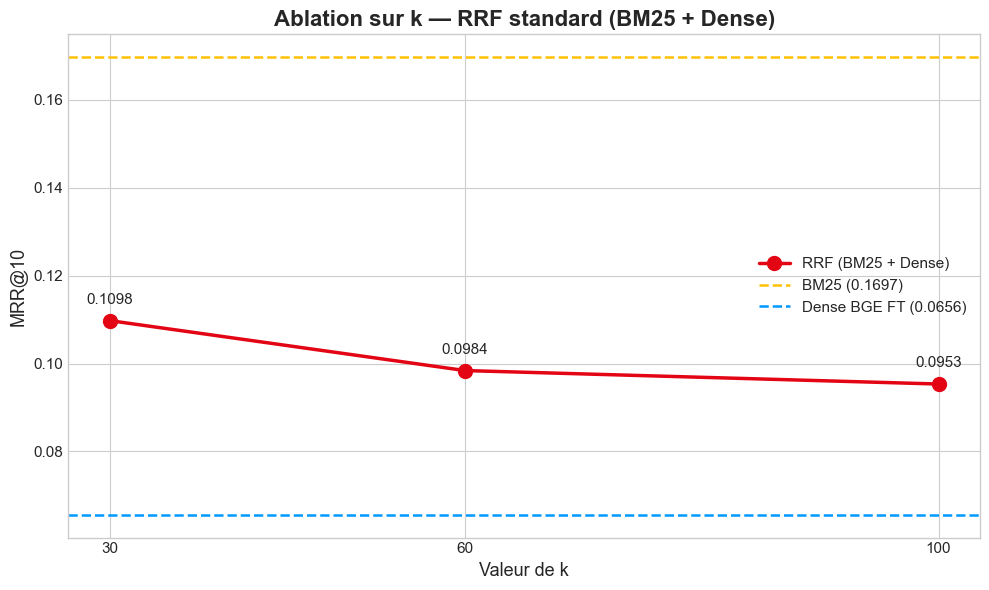

Figure sauvegardée : ../results/analysis/06_rrf_weighted/rrf_k_ablation.png


In [5]:
# Valeurs de k à tester
k_values = [30, 60, 100]
mrr_per_k = []

for k in k_values:
    if bm25_run and dense_run:
        fused = rrf_fusion(bm25_run, dense_run, k=k)
        mrr = compute_mrr_at_10(fused, qrels)
    else:
        mrr = float('nan')
    mrr_per_k.append(mrr)
    print(f'k={k:3d}  MRR@10 = {mrr:.4f}')

# Lignes de référence (baselines)
mrr_bm25 = 0.1697    # BM25 sur corpus complet
mrr_dense = 0.0656   # Dense BGE-base FT (sous-ensemble 10%)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    k_values, mrr_per_k,
    marker='o', linewidth=2.5, markersize=10,
    color=COLORS[0], label='RRF (BM25 + Dense)'
)

# Annotations des valeurs RRF
for k, mrr in zip(k_values, mrr_per_k):
    if not np.isnan(mrr):
        ax.annotate(
            f'{mrr:.4f}', (k, mrr),
            textcoords='offset points', xytext=(0, 12), ha='center', fontsize=11
        )

# Lignes horizontales pour les baselines
ax.axhline(mrr_bm25, color=COLORS[1], linewidth=1.8, linestyle='--', label=f'BM25 ({mrr_bm25:.4f})')
ax.axhline(mrr_dense, color=COLORS[2], linewidth=1.8, linestyle='--', label=f'Dense BGE FT ({mrr_dense:.4f})')

ax.set_xlabel('Valeur de k', fontsize=13)
ax.set_ylabel('MRR@10', fontsize=13)
ax.set_title('Ablation sur k — RRF standard (BM25 + Dense)', fontsize=16, fontweight='bold')
ax.set_xticks(k_values)
ax.tick_params(axis='both', labelsize=11)
ax.legend(fontsize=11)

plt.tight_layout()
out_path = OUTPUT_DIR / 'rrf_k_ablation.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {out_path}')

## 4. Figure 2 — Heatmap RRF pondéré (grid search 20×20)

Grid search terminé.
Optimal : w1=0.00, w2=0.00 → MRR@10=0.1697


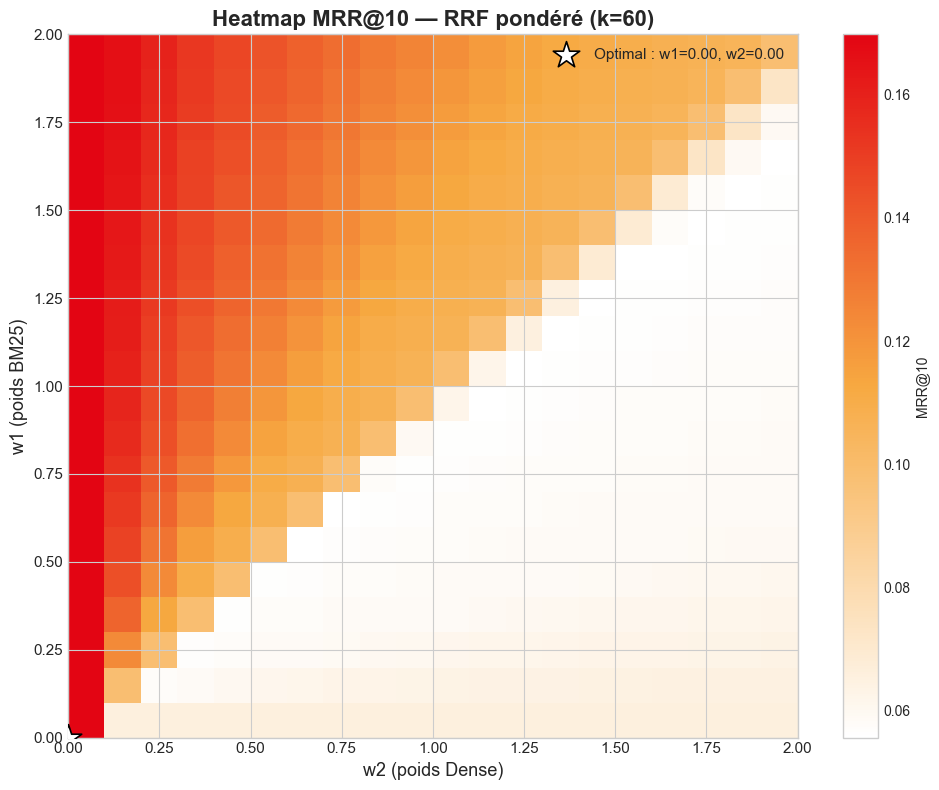

Figure sauvegardée : ../results/analysis/06_rrf_weighted/weighted_rrf_heatmap.png


In [6]:
# Grid search sur w1 et w2 dans [0, 2]
n_points = 20
w_range = np.linspace(0.0, 2.0, n_points)

mrr_grid = np.full((n_points, n_points), np.nan)

if bm25_run and dense_run and qrels:
    for i, w1 in enumerate(w_range):
        for j, w2 in enumerate(w_range):
            fused = weighted_rrf(bm25_run, dense_run, w1=w1, w2=w2, k=60)
            mrr_grid[i, j] = compute_mrr_at_10(fused, qrels)
    print('Grid search terminé.')
else:
    print('[INFO] Données manquantes — heatmap vide.')

# Recherche du point optimal
if not np.all(np.isnan(mrr_grid)):
    best_idx = np.unravel_index(np.nanargmax(mrr_grid), mrr_grid.shape)
    best_w1 = w_range[best_idx[0]]
    best_w2 = w_range[best_idx[1]]
    best_mrr = mrr_grid[best_idx]
    print(f'Optimal : w1={best_w1:.2f}, w2={best_w2:.2f} → MRR@10={best_mrr:.4f}')
else:
    best_w1, best_w2, best_mrr = 1.0, 1.0, float('nan')

# Heatmap avec colormap rouge
fig, ax = plt.subplots(figsize=(10, 8))

# Colormap dérivée du rouge (#e30513)
from matplotlib.colors import LinearSegmentedColormap
ulval_cmap = LinearSegmentedColormap.from_list(
    'ulval_red', ['#ffffff', '#f7a941', '#e30513'], N=256
)

im = ax.imshow(
    mrr_grid, origin='lower', aspect='auto',
    extent=[0, 2, 0, 2], cmap=ulval_cmap
)
plt.colorbar(im, ax=ax, label='MRR@10')

# Marqueur étoile au point optimal
ax.scatter(
    best_w2, best_w1, marker='*', s=400,
    color='white', edgecolors='black', linewidths=1.2,
    label=f'Optimal : w1={best_w1:.2f}, w2={best_w2:.2f}', zorder=5
)

ax.set_xlabel('w2 (poids Dense)', fontsize=13)
ax.set_ylabel('w1 (poids BM25)', fontsize=13)
ax.set_title('Heatmap MRR@10 — RRF pondéré (k=60)', fontsize=16, fontweight='bold')
ax.tick_params(axis='both', labelsize=11)
ax.legend(fontsize=11, loc='upper right')

plt.tight_layout()
out_path = OUTPUT_DIR / 'weighted_rrf_heatmap.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {out_path}')

## 5. Figure 3 — Comparaison BM25 / Dense / RRF / RRF pondéré

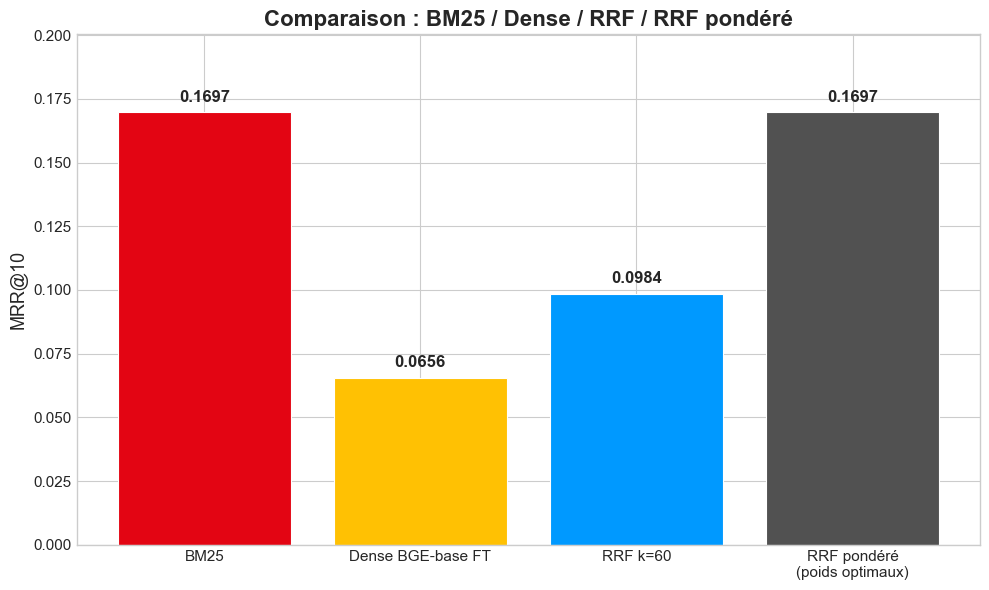

Figure sauvegardée : ../results/analysis/06_rrf_weighted/rrf_comparison.png


In [7]:
# Calcul du MRR@10 pour RRF standard k=60 et RRF pondéré optimal
if bm25_run and dense_run and qrels:
    rrf_std = rrf_fusion(bm25_run, dense_run, k=60)
    mrr_rrf_std = compute_mrr_at_10(rrf_std, qrels)

    rrf_opt = weighted_rrf(bm25_run, dense_run, w1=best_w1, w2=best_w2, k=60)
    mrr_rrf_opt = compute_mrr_at_10(rrf_opt, qrels)
else:
    mrr_rrf_std = float('nan')
    mrr_rrf_opt = float('nan')

# Valeurs de référence pré-calculées
mrr_bm25 = 0.1697
mrr_dense = 0.0656

method_names = ['BM25', 'Dense BGE-base FT', 'RRF k=60', 'RRF pondéré\n(poids optimaux)']
method_mrrs = [mrr_bm25, mrr_dense, mrr_rrf_std, mrr_rrf_opt]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    method_names, method_mrrs,
    color=COLORS[:len(method_names)], edgecolor='white', linewidth=0.8
)

# Valeurs sur les barres
for bar, val in zip(bars, method_mrrs):
    if not np.isnan(val):
        ax.text(
            bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
            f'{val:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold'
        )

ax.set_ylabel('MRR@10', fontsize=13)
ax.set_title('Comparaison : BM25 / Dense / RRF / RRF pondéré', fontsize=16, fontweight='bold')
ax.tick_params(axis='both', labelsize=11)
max_val = max(v for v in method_mrrs if not np.isnan(v))
ax.set_ylim(0, max_val * 1.18)

plt.tight_layout()
out_path = OUTPUT_DIR / 'rrf_comparison.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure sauvegardée : {out_path}')

## 6. Poids optimaux et gain sur le RRF standard

In [8]:
# Résumé des résultats
print('=' * 60)
print('RÉSULTATS RRF PONDÉRÉ')
print('=' * 60)
print(f'  BM25 (référence)       : MRR@10 = {mrr_bm25:.4f}')
print(f'  Dense BGE FT           : MRR@10 = {mrr_dense:.4f}')
print(f'  RRF standard (k=60)    : MRR@10 = {mrr_rrf_std:.4f}')
print(f'  RRF pondéré optimal    : MRR@10 = {mrr_rrf_opt:.4f}')
print()
print(f'  Poids optimaux         : w1 (BM25) = {best_w1:.2f}, w2 (Dense) = {best_w2:.2f}')
if not np.isnan(mrr_rrf_std) and not np.isnan(mrr_rrf_opt):
    delta = mrr_rrf_opt - mrr_rrf_std
    print(f'  Gain sur RRF standard  : +{delta:.4f} ({delta/mrr_rrf_std*100:.1f}%)')
print('=' * 60)

RÉSULTATS RRF PONDÉRÉ
  BM25 (référence)       : MRR@10 = 0.1697
  Dense BGE FT           : MRR@10 = 0.0656
  RRF standard (k=60)    : MRR@10 = 0.0984
  RRF pondéré optimal    : MRR@10 = 0.1697

  Poids optimaux         : w1 (BM25) = 0.00, w2 (Dense) = 0.00
  Gain sur RRF standard  : +0.0713 (72.5%)
